In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

sns.set_theme(style="whitegrid")

In [2]:
# Загрузка датасета
df = pd.read_csv("creditcard.csv")

X = df.drop(["Class", "Time"], axis=1)
y = df["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Данные успешно отмасштабированы. Первые 3 строки:")
print(np.round(X_train_scaled[:3], 2))

Данные успешно отмасштабированы. Первые 3 строки:
[[-0.43 -0.32  1.14 -0.57 -0.15 -0.06  0.05  0.23  0.48 -0.83  0.32  1.04
   0.08 -0.54 -1.92  0.38 -0.65  0.11  0.29  0.31  0.07  0.02  0.56  0.1
  -1.67  1.36  0.18  0.57  0.09]
 [-1.91 -0.52 -0.3  -1.71 -0.29 -0.08  0.1   0.47  0.88 -1.01 -0.02  0.51
  -0.36  0.34 -0.2   1.63 -1.47  1.03 -0.56 -2.03  0.04  0.86 -0.07  0.5
   0.31  0.77 -2.13  0.5   0.2 ]
 [-1.03  0.96 -0.35 -1.09  1.42 -0.29 -0.89 -3.46  0.65 -1.33 -1.58  0.42
   0.32 -1.66 -1.28  0.75  0.68  0.15 -1.15 -1.74  4.76 -2.95 -3.59 -1.82
  -0.45 -0.49  1.34  0.57  0.17]]


Значения примерно в одинаковом разбросе, кроме третьей строки, там есть значения сильно отклонены от остальных, скорее всего третья транзакция мошенническая. Также убрал столбец Time, т.к. он не имеет никаких полезных данных

In [3]:
rng = np.random.RandomState(42)

idx_fraud = np.where(y_train == 1)[0]
idx_norm = np.where(y_train == 0)[0]
idx_norm_sample = rng.choice(idx_norm, size=20000, replace=False)

idx = np.concatenate([idx_fraud, idx_norm_sample])

X_train_small = X_train_scaled[idx]
y_train_small = y_train.iloc[idx]

Слишком много данных поэтому уменьшаем выборку 

In [ ]:
svm_linear = SVC(
    kernel="linear",
    C=1.0,
    gamma="scale",
    random_state=42
)
svm_linear.fit(X_train_small, y_train_small)

y_pred_lin = svm_linear.predict(X_test_scaled)
acc_lin = accuracy_score(y_test, y_pred_lin)
print(f"Точность Линейного SVM: {acc_lin*100:.1f}%")

Точность Линейного SVM: 99.9%


Точность получилась 99.9%, но дисбаланс классов не показывает реального качества: почти весь тест состоит из обычных транзакций. Уменьшение выборки обычных транзакций ускорило обучение и все мошеннические транзакции сохранены.

In [6]:
svm_rbf = SVC(
    kernel="rbf",
    C=1.0,
    gamma="scale",
    random_state=42
)
svm_rbf.fit(X_train, y_train)

y_pred_rbf = svm_rbf.predict(X_test)
acc_rbf = accuracy_score(y_test, y_pred_rbf)
print(f"Точность Линейного SVM: {acc_rbf*100:.1f}%")
print(f"Из {len(X_train)} обучающих примеров опорных векторов - {len(svm_rbf.support_vectors_)}")

Точность Линейного SVM: 99.9%
Из 213605 обучающих примеров опорных векторов - 771


Точность осталась та же из-за дисбаланса данных и не показывает реального качества. Опорных вектооров очень мало - границу определяет мало количество точек. В датасете недостаточно данных мошеннеческих операций (492 мошеннические операции (ctrl+f = "1")), из-за чего модели тяжело понять паттерны

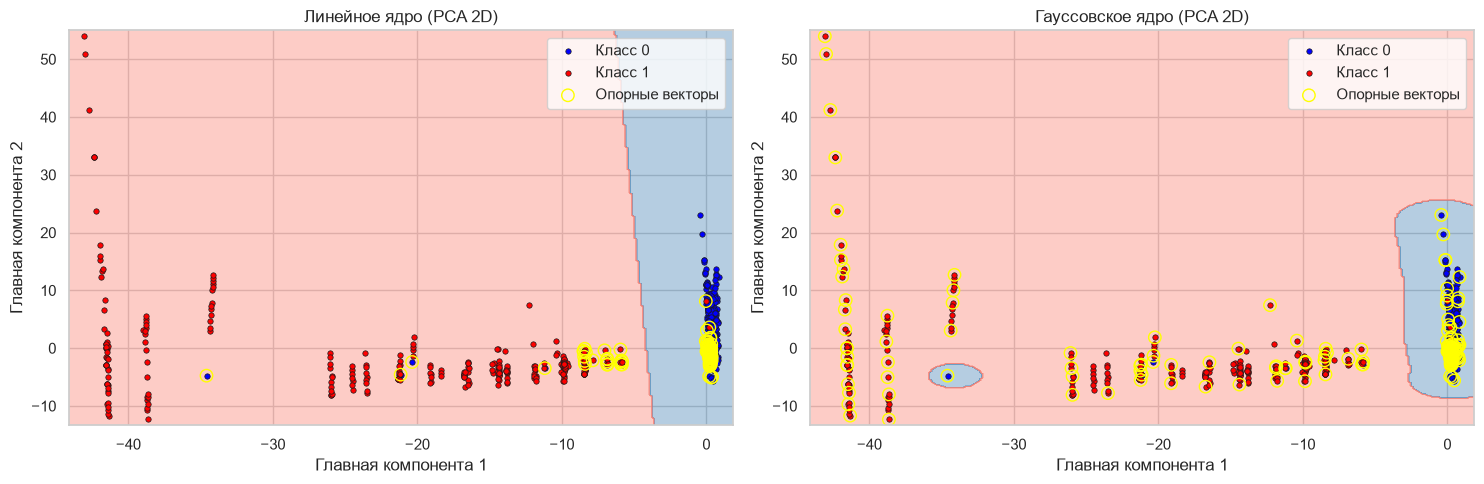

In [8]:
from sklearn.decomposition import PCA
from matplotlib.colors import ListedColormap

pca = PCA(n_components=2)
X_small_2d = pca.fit_transform(X_train_small)
X_test_2d = pca.transform(X_test_scaled)

svm_lin_2d = SVC(kernel="linear", C=1.0, random_state=42).fit(X_small_2d, y_train_small)
svm_rbf_2d = SVC(kernel="rbf", C=1.0, gamma="scale", random_state=42).fit(X_small_2d, y_train_small)

def plot_decision_boundary(model, X_set, y_set, ax, title):
    X1, X2 = np.meshgrid(
        np.linspace(X_set[:,0].min()-1, X_set[:,0].max()+1, 300),
        np.linspace(X_set[:,1].min()-1, X_set[:,1].max()+1, 300),
    )
    Z = model.predict(np.c_[X1.ravel(), X2.ravel()]).reshape(X1.shape)
    ax.contourf(X1, X2, Z, alpha=0.4, cmap=ListedColormap(("steelblue", "salmon")))

    for c, color in zip([0, 1], ["blue", "red"]):
        mask = (y_set == c)
        ax.scatter(X_set[mask,0], X_set[mask,1], color=color, s=15,
                   edgecolors="k", linewidth=0.5, label=f"Класс {c}")

    ax.scatter(model.support_vectors_[:,0], model.support_vectors_[:,1],
               s=80, facecolors="none", edgecolors="yellow", label="Опорные векторы")
    ax.set_title(title)
    ax.set_xlabel("Главная компонента 1")
    ax.set_ylabel("Главная компонента 2")
    ax.legend()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
plot_decision_boundary(svm_lin_2d, X_small_2d, y_train_small.values, axes[0], "Линейное ядро (PCA 2D)")
plot_decision_boundary(svm_rbf_2d, X_small_2d, y_train_small.values, axes[1], "Гауссовское ядро (PCA 2D)")
plt.tight_layout()
plt.show()

Главная компонента 1 и 2 - линейная комбинация признаков v1-v28 и amount. 
Линейное ядро отрезало обычные транзакции (синие точки) от мошеннеческих (красные точки), но на 99.9% как было выявлено ранее, т.к. часть красных точек находятся с обычными транзакциями и часть синих точек с мошеннеческими.
Гаусовское ядро гибко обводит обычные транзакции. Но тоже с 99.9%, ведь часть точек выделена не верно, хотя и была выделена одинокая синяя точка слева между -30 и -40
